# O'Hara-Rudy (ORd) 1D Chain Model
## Coupled Human Ventricular Cardiomyocytes Cable Simulation

This notebook implements a **1D cable (chain) model** of coupled human ventricular cardiomyocytes based on the O'Hara-Rudy dynamic (ORd) model.

### Steps:
1. Translates the original MATLAB ORd single-cell model to Python (NumPy)
2. Connects **N cells** into a 1D chain via gap-junction (diffusive) coupling
3. Integrates the system using **operator-splitting** (forward Euler + diffusion)
4. Visualizes action potential propagation along the chain

**How the chain coupling works**

Each cell's membrane voltage is coupled to its neighbours through gap junctions:

$$\frac{dV_i}{dt} = -\frac{I_{\text{ion},i}}{C_m} + \frac{D}{\Delta x^2}\left(V_{i-1} - 2V_i + V_{i+1}\right)$$

where $D$ is the diffusion coefficient (related to gap-junction conductance,
intracellular resistivity, and cell geometry), and $\Delta x$ is the cell-to-cell
spacing. No-flux (sealed-end) boundary conditions are applied at both ends of the chain.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time as timer
import warnings
from matplotlib.colors import Normalize
from matplotlib import cm

warnings.filterwarnings('ignore', category=RuntimeWarning)

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (12, 6)


## 1. Simulation Parameters (Adjustable)


In [2]:
# =====================================================================
# ADJUSTABLE SIMULATION PARAMETERS
# =====================================================================

# --- Chain geometry ---
n_cells   = 50        # Number of cells in the chain
dx        = 0.01      # Cell spacing (cm) — equals cell length L

# --- Gap-junction coupling ---
D_gap     = 0.0012    # Diffusion coefficient (cm^2/ms)
                       # ~0.0012 gives ~65 cm/s conduction velocity (normal)
                       # Reduce to simulate gap-junction remodelling / fibrosis
                       # Set to 0 for completely uncoupled cells

# --- Pacing protocol ---
CL        = 1000.0    # Pacing cycle length (ms) — 1000 = 1 Hz
n_beats   = 5         # Total beats (only last beat is recorded; ~10 min for 50 cells)
stim_cells = list(range(5))  # Which cells receive the stimulus (first 5)
stim_amp  = -80.0     # Stimulus amplitude (uA/uF)
stim_dur  = 1.0       # Stimulus duration (ms) — 1.0 is needed for forward Euler stability

# --- Integration ---
dt        = 0.02      # Time step (ms) — 0.02 is stable for forward Euler
record_dt = 0.2       # Recording resolution (ms) — every 10th step


#_____________________________________________
# --- Cell types along the chain ---
# 0 = endocardial, 1 = epicardial, 2 = midmyocardial (M-cell)
# Default: transmural fibre (endo -> M -> epi)
#celltypes = np.zeros(n_cells, dtype=int)
#endo_frac = 0.35   # fraction of cells that are endo
#m_frac    = 0.30   # fraction that are M-cells
#celltypes[:int(n_cells * endo_frac)] = 0                                # endo
#celltypes[int(n_cells * endo_frac):int(n_cells * (endo_frac + m_frac))] = 2  # M
#celltypes[int(n_cells * (endo_frac + m_frac)):] = 1                     # epi
#_______________________________________________
celltypes = np.zeros(n_cells, dtype=int)

# --- Extracellular ionic concentrations (mM) ---
nao = 140.0    # [Na+]o — decrease to simulate hyponatremia
cao = 1.8      # [Ca2+]o
ko  = 5.4      # [K+]o  — increase to simulate hyperkalemia

# --- Ion channel conductance scaling factors ---
# Multiply the default max conductance by these factors.
# Set < 1 to simulate channel block (drug effect), > 1 to upregulate.
scale_GNa   = 1.0   # Fast Na+ current (INa)
scale_GNaL  = 1.0   # Late Na+ current (INaL)
scale_Gto   = 1.0   # Transient outward K+ current (Ito)
scale_PCa   = 1.0   # L-type Ca2+ current (ICaL)
scale_GKr   = 1.0   # Rapid delayed rectifier K+ (IKr)  — hERG
scale_GKs   = 1.0   # Slow delayed rectifier K+ (IKs)
scale_GK1   = 1.0   # Inward rectifier K+ (IK1)
scale_Gncx  = 1.0   # Na+/Ca2+ exchanger (INaCa)
scale_Pnak  = 1.0   # Na+/K+ ATPase (INaK)
scale_GKb   = 1.0   # Background K+ (IKb)
scale_GpCa  = 1.0   # Sarcolemmal Ca2+ pump (IpCa)

print(f"Chain: {n_cells} cells, dx={dx} cm, D={D_gap} cm^2/ms")
print(f"Pacing: CL={CL} ms, {n_beats} beats, stim on cells {stim_cells[0]}-{stim_cells[-1]}")
print(f"Cell types: endo={np.sum(celltypes==0)}, M={np.sum(celltypes==2)}, epi={np.sum(celltypes==1)}")


Chain: 50 cells, dx=0.01 cm, D=0.0012 cm^2/ms
Pacing: CL=1000.0 ms, 5 beats, stim on cells 0-4
Cell types: endo=50, M=0, epi=0


## 2. ORd Single-Cell Model (Vectorized)

The function below computes the right-hand side (derivatives) of all 41 state
variables for **all cells simultaneously** using NumPy broadcasting.  
This is a direct, validated translation of the original MATLAB `model.m`,
with added numerical safeguards for the GHK current equations.

**State variables (41 per cell):**

| Index | Variable | Description |
|-------|----------|-------------|
| 0 | V | Membrane potential (mV) |
| 1-2 | Na_i, Na_ss | Intracellular [Na+], myoplasm & subspace |
| 3-4 | K_i, K_ss | Intracellular [K+] |
| 5-6 | Ca_i, Ca_ss | Intracellular [Ca2+] |
| 7-8 | Ca_nsr, Ca_jsr | SR [Ca2+], network & junctional |
| 9-14 | m, hf, hs, j, hsp, jp | INa gating |
| 15-17 | mL, hL, hLp | INaL gating |
| 18-23 | a, iF, iS, ap, iFp, iSp | Ito gating |
| 24-32 | d, ff, fs, fcaf, fcas, jca, nca, ffp, fcafp | ICaL gating |
| 33-34 | xrf, xrs | IKr gating |
| 35-36 | xs1, xs2 | IKs gating |
| 37 | xk1 | IK1 gating |
| 38-39 | Jrel_np, Jrel_p | RyR release |
| 40 | CaMKt | CaMKII trapped fraction |


In [3]:
def safe_exp(x, limit=500.0):
    """Clipped exponential to prevent overflow."""
    return np.exp(np.clip(x, -limit, limit))

def ghk(v_frt, z, c_in, c_out, Fara, R_gas, Temp):
    """
    Goldman-Hodgkin-Katz flux equation with safe handling near v=0.

    Returns z^2 * F^2/(RT) * v * (c_in * exp(z*v*F/RT) - c_out) / (exp(z*v*F/RT) - 1)
    """
    zvfrt = z * v_frt
    # Use Taylor expansion when |zvfrt| is small
    small = np.abs(zvfrt) < 1e-6
    e_zvfrt = safe_exp(zvfrt)

    # Normal GHK
    numer = c_in * e_zvfrt - c_out
    denom = e_zvfrt - 1.0
    # Avoid division by zero: where denom~0, use L'Hopital limit
    safe_denom = np.where(small, 1.0, denom)
    result_normal = z * Fara * Fara / (R_gas * Temp) * v_frt / z * z * (numer / safe_denom)

    # At v=0: limit is z*F*(c_in - c_out) — actually z^2*F^2/(RT) * (c_in - c_out)
    # More precisely: lim = z^2 * F^2 / (RT) * 1/z * (c_in - c_out) but let's just use:
    # vffrt * (c_in * exp(zvfrt) - c_out) / (exp(zvfrt) - 1)
    # = F^2/(RT) * v * (...) -> at v=0 -> z * F * (c_in - c_out) by L'Hopital
    result_small = z * Fara * (c_in - c_out)

    return np.where(small, result_small, result_normal)

print("Helper functions defined.")


Helper functions defined.


In [4]:

def ord_model(states, celltypes, params):
    """
    Compute derivatives for all cells (vectorized).

    Parameters
    ----------
    states : ndarray, shape (n_cells, 41)
        Current state variables for all cells.
    celltypes : ndarray, shape (n_cells,)
        Cell type per cell: 0=endo, 1=epi, 2=M.
    params : dict
        Physical constants, extracellular concentrations, conductance scales.

    Returns
    -------
    derivs : ndarray, shape (n_cells, 41)
        Time derivatives of all state variables.
    currents : dict
        Named ionic currents for the current time step.
    """
    n = states.shape[0]

    # Unpack parameters
    nao = params['nao']; cao = params['cao']; ko = params['ko']
    R_gas = 8314.0; Temp = 310.0; Fara = 96485.0

    # Cell geometry
    L = 0.01; rad = 0.0011
    vcell = 1000 * 3.14 * rad * rad * L
    Ageo = 2 * 3.14 * rad * rad + 2 * 3.14 * rad * L
    Acap = 2 * Ageo
    vmyo = 0.68 * vcell
    vnsr = 0.0552 * vcell
    vjsr = 0.0048 * vcell
    vss = 0.02 * vcell

    # Conductance scale factors
    sGNa  = params['scale_GNa'];  sGNaL = params['scale_GNaL']
    sGto  = params['scale_Gto'];  sPCa  = params['scale_PCa']
    sGKr  = params['scale_GKr'];  sGKs  = params['scale_GKs']
    sGK1  = params['scale_GK1'];  sGncx = params['scale_Gncx']
    sPnak = params['scale_Pnak']; sGKb  = params['scale_GKb']
    sGpCa = params['scale_GpCa']

    # Unpack state variables — each is shape (n,)
    v     = states[:, 0]
    nai   = np.maximum(states[:, 1], 1e-12)
    nass  = np.maximum(states[:, 2], 1e-12)
    ki    = np.maximum(states[:, 3], 1e-12)
    kss   = np.maximum(states[:, 4], 1e-12)
    cai   = np.maximum(states[:, 5], 1e-12)
    cass  = np.maximum(states[:, 6], 1e-12)
    cansr = np.maximum(states[:, 7], 1e-12)
    cajsr = np.maximum(states[:, 8], 1e-12)
    m_gate = np.clip(states[:, 9], 0, 1)
    hf    = np.clip(states[:, 10], 0, 1)
    hs    = np.clip(states[:, 11], 0, 1)
    j_gate = np.clip(states[:, 12], 0, 1)
    hsp   = np.clip(states[:, 13], 0, 1)
    jp    = np.clip(states[:, 14], 0, 1)
    mL    = np.clip(states[:, 15], 0, 1)
    hL    = np.clip(states[:, 16], 0, 1)
    hLp   = np.clip(states[:, 17], 0, 1)
    a_gate = np.clip(states[:, 18], 0, 1)
    iF    = np.clip(states[:, 19], 0, 1)
    iS    = np.clip(states[:, 20], 0, 1)
    ap    = np.clip(states[:, 21], 0, 1)
    iFp   = np.clip(states[:, 22], 0, 1)
    iSp   = np.clip(states[:, 23], 0, 1)
    d_gate = np.clip(states[:, 24], 0, 1)
    ff    = np.clip(states[:, 25], 0, 1)
    fs    = np.clip(states[:, 26], 0, 1)
    fcaf  = np.clip(states[:, 27], 0, 1)
    fcas  = np.clip(states[:, 28], 0, 1)
    jca   = np.clip(states[:, 29], 0, 1)
    nca   = np.clip(states[:, 30], 0, 1)
    ffp   = np.clip(states[:, 31], 0, 1)
    fcafp = np.clip(states[:, 32], 0, 1)
    xrf   = np.clip(states[:, 33], 0, 1)
    xrs   = np.clip(states[:, 34], 0, 1)
    xs1   = np.clip(states[:, 35], 0, 1)
    xs2   = np.clip(states[:, 36], 0, 1)
    xk1   = np.clip(states[:, 37], 0, 1)
    Jrelnp = states[:, 38]
    Jrelp  = states[:, 39]
    CaMKt  = np.clip(states[:, 40], 0, 1)

    # Cell-type masks
    is_epi = (celltypes == 1)
    is_M   = (celltypes == 2)

    # ---- CaMK ----
    KmCaMK = 0.15
    aCaMK_const = 0.05; bCaMK = 0.00068; CaMKo = 0.05; KmCaM = 0.0015
    CaMKb = CaMKo * (1.0 - CaMKt) / (1.0 + KmCaM / cass)
    CaMKa = CaMKb + CaMKt
    dCaMKt = aCaMK_const * CaMKb * (CaMKb + CaMKt) - bCaMK * CaMKt

    # ---- Reversal potentials ----
    ENa = (R_gas * Temp / Fara) * np.log(nao / nai)
    EK  = (R_gas * Temp / Fara) * np.log(ko / ki)
    PKNa = 0.01833
    EKs = (R_gas * Temp / Fara) * np.log((ko + PKNa * nao) / (ki + PKNa * nai))

    vffrt = v * Fara * Fara / (R_gas * Temp)
    vfrt  = v * Fara / (R_gas * Temp)

    # ---- INa ----
    mss = 1.0 / (1.0 + safe_exp((-(v + 39.57)) / 9.871))
    tm  = 1.0 / (6.765 * safe_exp((v + 11.64) / 34.77) + 8.552 * safe_exp(-(v + 77.42) / 5.955))
    dm  = (mss - m_gate) / tm

    hss = 1.0 / (1.0 + safe_exp((v + 82.90) / 6.086))
    thf = 1.0 / (1.432e-5 * safe_exp(-(v + 1.196) / 6.285) + 6.149 * safe_exp((v + 0.5096) / 20.27))
    ths = 1.0 / (0.009794 * safe_exp(-(v + 17.95) / 28.05) + 0.3343 * safe_exp((v + 5.730) / 56.66))
    Ahf = 0.99; Ahs = 1.0 - Ahf
    dhf = (hss - hf) / thf
    dhs = (hss - hs) / ths
    h = Ahf * hf + Ahs * hs

    jss = hss
    tj = 2.038 + 1.0 / (0.02136 * safe_exp(-(v + 100.6) / 8.281) + 0.3052 * safe_exp((v + 0.9941) / 38.45))
    dj = (jss - j_gate) / tj

    hssp = 1.0 / (1.0 + safe_exp((v + 89.1) / 6.086))
    thsp = 3.0 * ths
    dhsp = (hssp - hsp) / thsp
    hp = Ahf * hf + Ahs * hsp

    tjp = 1.46 * tj
    djp = (jss - jp) / tjp

    GNa = 75.0 * sGNa
    fINap = 1.0 / (1.0 + KmCaMK / CaMKa)
    INa = GNa * (v - ENa) * m_gate**3 * ((1.0 - fINap) * h * j_gate + fINap * hp * jp)

    # ---- INaL ----
    mLss = 1.0 / (1.0 + safe_exp((-(v + 42.85)) / 5.264))
    tmL = tm
    dmL = (mLss - mL) / tmL
    hLss = 1.0 / (1.0 + safe_exp((v + 87.61) / 7.488))
    thL = 200.0
    dhL = (hLss - hL) / thL
    hLssp = 1.0 / (1.0 + safe_exp((v + 93.81) / 7.488))
    thLp = 3.0 * thL
    dhLp = (hLssp - hLp) / thLp
    GNaL = 0.0075 * sGNaL
    GNaL = np.where(is_epi, GNaL * 0.6, GNaL)
    fINaLp = 1.0 / (1.0 + KmCaMK / CaMKa)
    INaL = GNaL * (v - ENa) * mL * ((1.0 - fINaLp) * hL + fINaLp * hLp)

    # ---- Ito ----
    ass = 1.0 / (1.0 + safe_exp((-(v - 14.34)) / 14.82))
    ta  = 1.0515 / (1.0 / (1.2089 * (1.0 + safe_exp(-(v - 18.4099) / 29.3814))) + 3.5 / (1.0 + safe_exp((v + 100.0) / 29.3814)))
    da  = (ass - a_gate) / ta
    iss = 1.0 / (1.0 + safe_exp((v + 43.94) / 5.711))
    delta_epi = np.where(is_epi, 1.0 - (0.95 / (1.0 + safe_exp((v + 70.0) / 5.0))), 1.0)
    tiF = (4.562 + 1.0 / (0.3933 * safe_exp(-(v + 100.0) / 100.0) + 0.08004 * safe_exp((v + 50.0) / 16.59))) * delta_epi
    tiS = (23.62 + 1.0 / (0.001416 * safe_exp(-(v + 96.52) / 59.05) + 1.780e-8 * safe_exp((v + 114.1) / 8.079))) * delta_epi
    AiF = 1.0 / (1.0 + safe_exp((v - 213.6) / 151.2))
    AiS = 1.0 - AiF
    diF = (iss - iF) / tiF
    diS = (iss - iS) / tiS
    i_gate = AiF * iF + AiS * iS
    assp = 1.0 / (1.0 + safe_exp((-(v - 24.34)) / 14.82))
    dap = (assp - ap) / ta
    dti_develop = 1.354 + 1.0e-4 / (safe_exp((v - 167.4) / 15.89) + safe_exp(-(v - 12.23) / 0.2154))
    dti_recover = 1.0 - 0.5 / (1.0 + safe_exp((v + 70.0) / 20.0))
    tiFp = dti_develop * dti_recover * tiF
    tiSp = dti_develop * dti_recover * tiS
    diFp = (iss - iFp) / tiFp
    diSp = (iss - iSp) / tiSp
    ip = AiF * iFp + AiS * iSp
    Gto = 0.02 * sGto
    Gto = np.where(is_epi | is_M, Gto * 4.0, Gto)
    fItop = 1.0 / (1.0 + KmCaMK / CaMKa)
    Ito = Gto * (v - EK) * ((1.0 - fItop) * a_gate * i_gate + fItop * ap * ip)

    # ---- ICaL, ICaNa, ICaK (with safe GHK) ----
    dss = 1.0 / (1.0 + safe_exp((-(v + 3.940)) / 4.230))
    td  = 0.6 + 1.0 / (safe_exp(-0.05 * (v + 6.0)) + safe_exp(0.09 * (v + 14.0)))
    dd  = (dss - d_gate) / td
    fss = 1.0 / (1.0 + safe_exp((v + 19.58) / 3.696))
    tff = 7.0 + 1.0 / (0.0045 * safe_exp(-(v + 20.0) / 10.0) + 0.0045 * safe_exp((v + 20.0) / 10.0))
    tfs = 1000.0 + 1.0 / (0.000035 * safe_exp(-(v + 5.0) / 4.0) + 0.000035 * safe_exp((v + 5.0) / 6.0))
    Aff = 0.6; Afs = 1.0 - Aff
    dff = (fss - ff) / tff
    dfs = (fss - fs) / tfs
    f_gate = Aff * ff + Afs * fs
    fcass = fss
    tfcaf = 7.0 + 1.0 / (0.04 * safe_exp(-(v - 4.0) / 7.0) + 0.04 * safe_exp((v - 4.0) / 7.0))
    tfcas = 100.0 + 1.0 / (0.00012 * safe_exp(-v / 3.0) + 0.00012 * safe_exp(v / 7.0))
    Afcaf = 0.3 + 0.6 / (1.0 + safe_exp((v - 10.0) / 10.0))
    Afcas = 1.0 - Afcaf
    dfcaf = (fcass - fcaf) / tfcaf
    dfcas = (fcass - fcas) / tfcas
    fca = Afcaf * fcaf + Afcas * fcas
    tjca_val = 75.0
    djca = (fcass - jca) / tjca_val
    tffp_val = 2.5 * tff
    dffp = (fss - ffp) / tffp_val
    fp_gate = Aff * ffp + Afs * fs
    tfcafp_val = 2.5 * tfcaf
    dfcafp = (fcass - fcafp) / tfcafp_val
    fcap = Afcaf * fcafp + Afcas * fcas
    Kmn = 0.002; k2n = 1000.0
    km2n = jca * 1.0
    anca = 1.0 / (k2n / np.maximum(km2n, 1e-12) + (1.0 + Kmn / cass)**4.0)
    dnca = anca * k2n - nca * km2n

    # GHK flux equations with safe exponentials
    evfrt  = safe_exp(vfrt)
    e2vfrt = safe_exp(2.0 * vfrt)

    # PhiCaL = 4 * vffrt * (cass*exp(2*vfrt) - 0.341*cao) / (exp(2*vfrt) - 1)
    denom_2 = e2vfrt - 1.0
    denom_2_safe = np.where(np.abs(denom_2) < 1e-7, 1.0, denom_2)
    PhiCaL_normal = 4.0 * vffrt * (cass * e2vfrt - 0.341 * cao) / denom_2_safe
    PhiCaL_limit = 4.0 * Fara * (cass - 0.341 * cao)  # limit as v->0
    PhiCaL = np.where(np.abs(denom_2) < 1e-7, PhiCaL_limit, PhiCaL_normal)

    # PhiCaNa = vffrt * (0.75*nass*exp(vfrt) - 0.75*nao) / (exp(vfrt) - 1)
    denom_1 = evfrt - 1.0
    denom_1_safe = np.where(np.abs(denom_1) < 1e-7, 1.0, denom_1)
    PhiCaNa_normal = 1.0 * vffrt * (0.75 * nass * evfrt - 0.75 * nao) / denom_1_safe
    PhiCaNa_limit = Fara * 0.75 * (nass - nao)
    PhiCaNa = np.where(np.abs(denom_1) < 1e-7, PhiCaNa_limit, PhiCaNa_normal)

    # PhiCaK
    PhiCaK_normal = 1.0 * vffrt * (0.75 * kss * evfrt - 0.75 * ko) / denom_1_safe
    PhiCaK_limit = Fara * 0.75 * (kss - ko)
    PhiCaK = np.where(np.abs(denom_1) < 1e-7, PhiCaK_limit, PhiCaK_normal)

    PCa_base = 0.0001 * sPCa
    PCa = np.where(is_epi, PCa_base * 1.2, np.where(is_M, PCa_base * 2.5, PCa_base))
    PCap = 1.1 * PCa
    PCaNa  = 0.00125 * PCa;  PCaK  = 3.574e-4 * PCa
    PCaNap = 0.00125 * PCap;  PCaKp = 3.574e-4 * PCap
    fICaLp = 1.0 / (1.0 + KmCaMK / CaMKa)
    ICaL  = ((1.0 - fICaLp) * PCa * PhiCaL * d_gate * (f_gate * (1.0 - nca) + jca * fca * nca)
           + fICaLp * PCap * PhiCaL * d_gate * (fp_gate * (1.0 - nca) + jca * fcap * nca))
    ICaNa = ((1.0 - fICaLp) * PCaNa * PhiCaNa * d_gate * (f_gate * (1.0 - nca) + jca * fca * nca)
           + fICaLp * PCaNap * PhiCaNa * d_gate * (fp_gate * (1.0 - nca) + jca * fcap * nca))
    ICaK  = ((1.0 - fICaLp) * PCaK * PhiCaK * d_gate * (f_gate * (1.0 - nca) + jca * fca * nca)
           + fICaLp * PCaKp * PhiCaK * d_gate * (fp_gate * (1.0 - nca) + jca * fcap * nca))

    # ---- IKr ----
    xrss = 1.0 / (1.0 + safe_exp((-(v + 8.337)) / 6.789))
    txrf = 12.98 + 1.0 / (0.3652 * safe_exp((v - 31.66) / 3.869) + 4.123e-5 * safe_exp(-(v - 47.78) / 20.38))
    txrs = 1.865 + 1.0 / (0.06629 * safe_exp((v - 34.70) / 7.355) + 1.128e-5 * safe_exp(-(v - 29.74) / 25.94))
    Axrf = 1.0 / (1.0 + safe_exp((v + 54.81) / 38.21))
    Axrs = 1.0 - Axrf
    dxrf = (xrss - xrf) / txrf
    dxrs = (xrss - xrs) / txrs
    xr = Axrf * xrf + Axrs * xrs
    rkr = 1.0 / (1.0 + safe_exp((v + 55.0) / 75.0)) * 1.0 / (1.0 + safe_exp((v - 10.0) / 30.0))
    GKr_base = 0.046 * sGKr
    GKr = np.where(is_epi, GKr_base * 1.3, np.where(is_M, GKr_base * 0.8, GKr_base))
    IKr = GKr * np.sqrt(ko / 5.4) * xr * rkr * (v - EK)

    # ---- IKs ----
    xs1ss = 1.0 / (1.0 + safe_exp((-(v + 11.60)) / 8.932))
    txs1 = 817.3 + 1.0 / (2.326e-4 * safe_exp((v + 48.28) / 17.80) + 0.001292 * safe_exp(-(v + 210.0) / 230.0))
    dxs1 = (xs1ss - xs1) / txs1
    xs2ss = xs1ss
    txs2 = 1.0 / (0.01 * safe_exp((v - 50.0) / 20.0) + 0.0193 * safe_exp(-(v + 66.54) / 31.0))
    dxs2 = (xs2ss - xs2) / txs2
    KsCa = 1.0 + 0.6 / (1.0 + (3.8e-5 / cai)**1.4)
    GKs_base = 0.0034 * sGKs
    GKs = np.where(is_epi, GKs_base * 1.4, GKs_base)
    IKs = GKs * KsCa * xs1 * xs2 * (v - EKs)

    # ---- IK1 ----
    xk1ss = 1.0 / (1.0 + safe_exp(-(v + 2.5538 * ko + 144.59) / (1.5692 * ko + 3.8115)))
    txk1 = 122.2 / (safe_exp(-(v + 127.2) / 20.36) + safe_exp((v + 236.8) / 69.33))
    dxk1 = (xk1ss - xk1) / txk1
    rk1 = 1.0 / (1.0 + safe_exp((v + 105.8 - 2.6 * ko) / 9.493))
    GK1_base = 0.1908 * sGK1
    GK1 = np.where(is_epi, GK1_base * 1.2, np.where(is_M, GK1_base * 1.3, GK1_base))
    IK1 = GK1 * np.sqrt(ko) * rk1 * xk1 * (v - EK)

    # ---- INaCa_i (intracellular) ----
    kna1 = 15.0; kna2 = 5.0; kna3 = 88.12; kasymm = 12.5
    wna = 6.0e4; wca = 6.0e4; wnaca = 5.0e3
    kcaon = 1.5e6; kcaoff = 5.0e3
    qna = 0.5224; qca = 0.1670
    hca = safe_exp(qca * v * Fara / (R_gas * Temp))
    hna = safe_exp(qna * v * Fara / (R_gas * Temp))

    h1_i = 1 + nai / kna3 * (1 + hna)
    h2_i = (nai * hna) / (kna3 * h1_i)
    h3_i = 1.0 / h1_i
    h4_i = 1.0 + nai / kna1 * (1 + nai / kna2)
    h5_i = nai * nai / (h4_i * kna1 * kna2)
    h6_i = 1.0 / h4_i
    h7_i = 1.0 + nao / kna3 * (1.0 + 1.0 / np.maximum(hna, 1e-30))
    h8_i = nao / (kna3 * np.maximum(hna, 1e-30) * h7_i)
    h9_i = 1.0 / h7_i
    h10_i = kasymm + 1.0 + nao / kna1 * (1.0 + nao / kna2)
    h11_i = nao * nao / (h10_i * kna1 * kna2)
    h12_i = 1.0 / h10_i
    k1_i = h12_i * cao * kcaon; k2_i = kcaoff
    k3p_i = h9_i * wca; k3pp_i = h8_i * wnaca; k3_i = k3p_i + k3pp_i
    k4p_i = h3_i * wca / np.maximum(hca, 1e-30); k4pp_i = h2_i * wnaca; k4_i = k4p_i + k4pp_i
    k5_i = kcaoff; k6_i = h6_i * cai * kcaon
    k7_i = h5_i * h2_i * wna; k8_i = h8_i * h11_i * wna
    x1_i = k2_i * k4_i * (k7_i + k6_i) + k5_i * k7_i * (k2_i + k3_i)
    x2_i = k1_i * k7_i * (k4_i + k5_i) + k4_i * k6_i * (k1_i + k8_i)
    x3_i = k1_i * k3_i * (k7_i + k6_i) + k8_i * k6_i * (k2_i + k3_i)
    x4_i = k2_i * k8_i * (k4_i + k5_i) + k3_i * k5_i * (k1_i + k8_i)
    xsum_i = x1_i + x2_i + x3_i + x4_i
    xsum_i = np.maximum(xsum_i, 1e-30)
    E1_i = x1_i / xsum_i; E2_i = x2_i / xsum_i
    E3_i = x3_i / xsum_i; E4_i = x4_i / xsum_i
    KmCaAct = 150.0e-6
    allo_i = 1.0 / (1.0 + (KmCaAct / cai)**2.0)
    zna_val = 1.0; zca_val = 2.0
    JncxNa_i = 3.0 * (E4_i * k7_i - E1_i * k8_i) + E3_i * k4pp_i - E2_i * k3pp_i
    JncxCa_i = E2_i * k2_i - E1_i * k1_i
    Gncx_base = 0.0008 * sGncx
    Gncx = np.where(is_epi, Gncx_base * 1.1, np.where(is_M, Gncx_base * 1.4, Gncx_base))
    INaCa_i = 0.8 * Gncx * allo_i * (zna_val * JncxNa_i + zca_val * JncxCa_i)

    # ---- INaCa_ss (subspace) ----
    h1_ss = 1 + nass / kna3 * (1 + hna)
    h2_ss = (nass * hna) / (kna3 * h1_ss)
    h3_ss = 1.0 / h1_ss
    h4_ss = 1.0 + nass / kna1 * (1 + nass / kna2)
    h5_ss = nass * nass / (h4_ss * kna1 * kna2)
    h6_ss = 1.0 / h4_ss
    h7_ss = h7_i  # same (uses nao, hna)
    h8_ss = h8_i
    h9_ss = h9_i
    h10_ss = kasymm + 1.0 + nao / kna1 * (1 + nao / kna2)
    h11_ss = nao * nao / (h10_ss * kna1 * kna2)
    h12_ss = 1.0 / h10_ss
    k1_ss = h12_ss * cao * kcaon; k2_ss = kcaoff
    k3p_ss = h9_ss * wca; k3pp_ss = h8_ss * wnaca; k3_ss = k3p_ss + k3pp_ss
    k4p_ss = h3_ss * wca / np.maximum(hca, 1e-30); k4pp_ss = h2_ss * wnaca; k4_ss = k4p_ss + k4pp_ss
    k5_ss = kcaoff; k6_ss = h6_ss * cass * kcaon
    k7_ss = h5_ss * h2_ss * wna; k8_ss = h8_ss * h11_ss * wna
    x1_ss = k2_ss * k4_ss * (k7_ss + k6_ss) + k5_ss * k7_ss * (k2_ss + k3_ss)
    x2_ss = k1_ss * k7_ss * (k4_ss + k5_ss) + k4_ss * k6_ss * (k1_ss + k8_ss)
    x3_ss = k1_ss * k3_ss * (k7_ss + k6_ss) + k8_ss * k6_ss * (k2_ss + k3_ss)
    x4_ss = k2_ss * k8_ss * (k4_ss + k5_ss) + k3_ss * k5_ss * (k1_ss + k8_ss)
    xsum_ss = x1_ss + x2_ss + x3_ss + x4_ss
    xsum_ss = np.maximum(xsum_ss, 1e-30)
    E1_ss = x1_ss / xsum_ss; E2_ss = x2_ss / xsum_ss
    E3_ss = x3_ss / xsum_ss; E4_ss = x4_ss / xsum_ss
    allo_ss = 1.0 / (1.0 + (KmCaAct / cass)**2.0)
    JncxNa_ss = 3.0 * (E4_ss * k7_ss - E1_ss * k8_ss) + E3_ss * k4pp_ss - E2_ss * k3pp_ss
    JncxCa_ss = E2_ss * k2_ss - E1_ss * k1_ss
    INaCa_ss = 0.2 * Gncx * allo_ss * (zna_val * JncxNa_ss + zca_val * JncxCa_ss)

    # ---- INaK ----
    k1p_nak = 949.5; k1m_nak = 182.4; k2p_nak = 687.2; k2m_nak = 39.4
    k3p_nak = 1899.0; k3m_nak = 79300.0; k4p_nak = 639.0; k4m_nak = 40.0
    Knai0 = 9.073; Knao0 = 27.78; delta_nak = -0.1550
    Knai_nak = Knai0 * safe_exp(delta_nak * v * Fara / (3.0 * R_gas * Temp))
    Knao_nak = Knao0 * safe_exp((1.0 - delta_nak) * v * Fara / (3.0 * R_gas * Temp))
    Kki_nak = 0.5; Kko_nak = 0.3582
    MgADP = 0.05; MgATP = 9.8; Kmgatp = 1.698e-7
    H_nak = 1.0e-7; eP = 4.2; Khp = 1.698e-7; Knap = 224.0; Kxkur = 292.0
    P_nak = eP / (1.0 + H_nak / Khp + nai / Knap + ki / Kxkur)
    denom_nak = (1.0 + nai / Knai_nak)**3.0 + (1.0 + ki / Kki_nak)**2.0 - 1.0
    denom_nak = np.maximum(denom_nak, 1e-30)
    a1_nak = (k1p_nak * (nai / Knai_nak)**3.0) / denom_nak
    b1_nak = k1m_nak * MgADP
    a2_nak = k2p_nak
    denom_nak_o = (1.0 + nao / Knao_nak)**3.0 + (1.0 + ko / Kko_nak)**2.0 - 1.0
    denom_nak_o = np.maximum(denom_nak_o, 1e-30)
    b2_nak = (k2m_nak * (nao / Knao_nak)**3.0) / denom_nak_o
    a3_nak = (k3p_nak * (ko / Kko_nak)**2.0) / denom_nak_o
    b3_nak = (k3m_nak * P_nak * H_nak) / (1.0 + MgATP / Kmgatp)
    a4_nak = (k4p_nak * MgATP / Kmgatp) / (1.0 + MgATP / Kmgatp)
    b4_nak = (k4m_nak * (ki / Kki_nak)**2.0) / denom_nak
    x1_nak = a4_nak * a1_nak * a2_nak + b2_nak * b4_nak * b3_nak + a2_nak * b4_nak * b3_nak + b3_nak * a1_nak * a2_nak
    x2_nak = b2_nak * b1_nak * b4_nak + a1_nak * a2_nak * a3_nak + a3_nak * b1_nak * b4_nak + a2_nak * a3_nak * b4_nak
    x3_nak = a2_nak * a3_nak * a4_nak + b3_nak * b2_nak * b1_nak + b2_nak * b1_nak * a4_nak + a3_nak * a4_nak * b1_nak
    x4_nak = b4_nak * b3_nak * b2_nak + a3_nak * a4_nak * a1_nak + b2_nak * a4_nak * a1_nak + b3_nak * b2_nak * a1_nak
    xsum_nak = np.maximum(x1_nak + x2_nak + x3_nak + x4_nak, 1e-30)
    E1_nak = x1_nak / xsum_nak; E2_nak = x2_nak / xsum_nak
    E3_nak = x3_nak / xsum_nak; E4_nak = x4_nak / xsum_nak
    zk_val = 1.0
    JnakNa = 3.0 * (E1_nak * a3_nak - E2_nak * b3_nak)
    JnakK  = 2.0 * (E4_nak * b1_nak - E3_nak * a1_nak)
    Pnak_base = 30 * sPnak
    Pnak = np.where(is_epi, Pnak_base * 0.9, np.where(is_M, Pnak_base * 0.7, Pnak_base))
    INaK = Pnak * (zna_val * JnakNa + zk_val * JnakK)

    # ---- IKb ----
    xkb = 1.0 / (1.0 + safe_exp(-(v - 14.48) / 18.34))
    GKb_base = 0.003 * sGKb
    GKb = np.where(is_epi, GKb_base * 0.6, GKb_base)
    IKb = GKb * xkb * (v - EK)

    # ---- INab (with safe GHK) ----
    PNab = 3.75e-10
    INab_normal = PNab * vffrt * (nai * evfrt - nao) / denom_1_safe
    INab_limit = PNab * Fara * (nai - nao)
    INab = np.where(np.abs(denom_1) < 1e-7, INab_limit, INab_normal)

    # ---- ICab (with safe GHK) ----
    PCab = 2.5e-8
    ICab_normal = PCab * 4.0 * vffrt * (cai * e2vfrt - 0.341 * cao) / denom_2_safe
    ICab_limit = PCab * 4.0 * Fara * (cai - 0.341 * cao)
    ICab = np.where(np.abs(denom_2) < 1e-7, ICab_limit, ICab_normal)

    # ---- IpCa ----
    GpCa_val = 0.0005 * sGpCa
    IpCa = GpCa_val * cai / (0.0005 + cai)

    # ---- Membrane voltage (no stimulus — added in main loop) ----
    dv = -(INa + INaL + Ito + ICaL + ICaNa + ICaK + IKr + IKs + IK1
          + INaCa_i + INaCa_ss + INaK + INab + IKb + IpCa + ICab)

    # ---- Diffusion fluxes ----
    JdiffNa = (nass - nai) / 2.0
    JdiffK  = (kss - ki)   / 2.0
    Jdiff   = (cass - cai)  / 0.2

    # ---- RyR release ----
    bt = 4.75
    a_rel = 0.5 * bt
    Jrel_inf_raw = a_rel * (-ICaL) / (1.0 + (1.5 / cajsr)**8.0)
    Jrel_inf = np.where(is_M, Jrel_inf_raw * 1.7, Jrel_inf_raw)
    tau_rel = np.maximum(bt / (1.0 + 0.0123 / cajsr), 0.001)
    dJrelnp = (Jrel_inf - Jrelnp) / tau_rel
    btp = 1.25 * bt
    a_relp = 0.5 * btp
    Jrel_infp_raw = a_relp * (-ICaL) / (1.0 + (1.5 / cajsr)**8.0)
    Jrel_infp = np.where(is_M, Jrel_infp_raw * 1.7, Jrel_infp_raw)
    tau_relp = np.maximum(btp / (1.0 + 0.0123 / cajsr), 0.001)
    dJrelp = (Jrel_infp - Jrelp) / tau_relp
    fJrelp = 1.0 / (1.0 + KmCaMK / CaMKa)
    Jrel = (1.0 - fJrelp) * Jrelnp + fJrelp * Jrelp

    # ---- SERCA uptake ----
    Jupnp = 0.004375 * cai / (cai + 0.00092)
    Jupp  = 2.75 * 0.004375 * cai / (cai + 0.00092 - 0.00017)
    Jupnp = np.where(is_epi, Jupnp * 1.3, Jupnp)
    Jupp  = np.where(is_epi, Jupp * 1.3, Jupp)
    fJupp = 1.0 / (1.0 + KmCaMK / CaMKa)
    Jleak = 0.0039375 * cansr / 15.0
    Jup = (1.0 - fJupp) * Jupnp + fJupp * Jupp - Jleak

    # ---- Translocation ----
    Jtr = (cansr - cajsr) / 100.0

    # ---- Calcium buffers ----
    cmdnmax_base = 0.05
    cmdnmax = np.where(is_epi, cmdnmax_base * 1.3, cmdnmax_base)
    kmcmdn = 0.00238; trpnmax = 0.07; kmtrpn = 0.0005
    BSRmax = 0.047; KmBSR = 0.00087; BSLmax = 1.124; KmBSL = 0.0087
    csqnmax = 10.0; kmcsqn = 0.8

    # ---- Concentration derivatives ----
    dnai  = -(INa + INaL + 3.0 * INaCa_i + 3.0 * INaK + INab) * Acap / (Fara * vmyo) + JdiffNa * vss / vmyo
    dnass = -(ICaNa + 3.0 * INaCa_ss) * Acap / (Fara * vss) - JdiffNa
    # Note: Istim contribution to dki is handled in the main loop
    dki   = -(Ito + IKr + IKs + IK1 + IKb - 2.0 * INaK) * Acap / (Fara * vmyo) + JdiffK * vss / vmyo
    dkss  = -(ICaK) * Acap / (Fara * vss) - JdiffK
    Bcai = 1.0 / (1.0 + cmdnmax * kmcmdn / (kmcmdn + cai)**2.0 + trpnmax * kmtrpn / (kmtrpn + cai)**2.0)
    dcai = Bcai * (-(IpCa + ICab - 2.0 * INaCa_i) * Acap / (2.0 * Fara * vmyo) - Jup * vnsr / vmyo + Jdiff * vss / vmyo)
    Bcass = 1.0 / (1.0 + BSRmax * KmBSR / (KmBSR + cass)**2.0 + BSLmax * KmBSL / (KmBSL + cass)**2.0)
    dcass = Bcass * (-(ICaL - 2.0 * INaCa_ss) * Acap / (2.0 * Fara * vss) + Jrel * vjsr / vss - Jdiff)
    dcansr = Jup - Jtr * vjsr / vnsr
    Bcajsr = 1.0 / (1.0 + csqnmax * kmcsqn / (kmcsqn + cajsr)**2.0)
    dcajsr = Bcajsr * (Jtr - Jrel)

    # ---- Assemble derivatives (n_cells, 41) ----
    derivs = np.column_stack([
        dv, dnai, dnass, dki, dkss, dcai, dcass, dcansr, dcajsr,
        dm, dhf, dhs, dj, dhsp, djp, dmL, dhL, dhLp,
        da, diF, diS, dap, diFp, diSp,
        dd, dff, dfs, dfcaf, dfcas, djca, dnca, dffp, dfcafp,
        dxrf, dxrs, dxs1, dxs2, dxk1,
        dJrelnp, dJrelp, dCaMKt
    ])

    currents = {
        'INa': INa, 'INaL': INaL, 'Ito': Ito, 'ICaL': ICaL,
        'IKr': IKr, 'IKs': IKs, 'IK1': IK1,
        'INaCa_i': INaCa_i, 'INaCa_ss': INaCa_ss, 'INaK': INaK,
        'IKb': IKb, 'INab': INab, 'ICab': ICab, 'IpCa': IpCa,
        'Jrel': Jrel, 'Jup': Jup, 'Jleak': Jleak
    }

    return derivs, currents

print("Model function defined (with numerical safeguards).")


Model function defined (with numerical safeguards).


## 3. Chain Simulation Engine

The simulation uses **operator splitting** with forward Euler integration:

1. **Reaction step**: Compute ionic-current derivatives for each cell independently  
2. **Stimulus step**: Inject stimulus current into designated cells  
3. **Diffusion step**: Apply gap-junction coupling between neighbouring cell voltages  
4. **Update**: Advance all state variables by `dt`

This approach is standard in cardiac electrophysiology simulations and is much faster
than passing the full coupled system to a stiff ODE solver.


In [5]:
def run_chain_simulation(n_cells, celltypes, params):
    """
    Run the ORd 1D chain simulation.

    Returns
    -------
    t_rec : ndarray — recorded time points (ms)
    V_rec : ndarray, shape (n_time, n_cells) — voltage traces
    states_final : ndarray, shape (n_cells, 41) — final state
    """
    CL = params['CL']
    n_beats = params['n_beats']
    dt = params['dt']
    record_dt = params['record_dt']
    D = params['D_gap']
    dx = params['dx']
    stim_cells = params['stim_cells']
    stim_amp = params['stim_amp']
    stim_dur = params['stim_dur']

    D_dx2 = D / (dx * dx)

    # Initial conditions (from original MATLAB)
    ic = np.array([-87, 7, 7, 145, 145, 1.0e-4, 1.0e-4, 1.2, 1.2,
                   0, 1, 1, 1, 1, 1, 0, 1, 1,
                   0, 1, 1, 0, 1, 1,
                   0, 1, 1, 1, 1, 1, 0, 1, 1,
                   0, 0, 0, 0, 1,
                   0, 0, 0])

    states = np.tile(ic, (n_cells, 1))  # (n_cells, 41)

    steps_per_beat = int(CL / dt)
    record_interval = max(1, int(record_dt / dt))

    n_record = steps_per_beat // record_interval + 1
    V_rec = np.zeros((n_record, n_cells))
    t_rec = np.zeros(n_record)

    total_steps = steps_per_beat * n_beats

    print(f"Running {n_beats} beats x {steps_per_beat} steps = {total_steps:,} total steps")
    print(f"Recording last beat: {n_record} time points")

    start_time = timer.time()
    rec_idx = 0

    for beat in range(n_beats):
        is_last_beat = (beat == n_beats - 1)
        if is_last_beat:
            rec_idx = 0

        for step in range(steps_per_beat):
            t_in_beat = step * dt

            # 1. Compute reaction derivatives
            derivs, _ = ord_model(states, celltypes, params)

            # 2. Add stimulus current
            if t_in_beat <= stim_dur:
                derivs[stim_cells, 0] -= stim_amp  # -(-80) = +80 depolarizes

            # 3. Add diffusion coupling to voltage (index 0)
            v = states[:, 0]
            if n_cells > 1 and D > 0:
                diff = np.zeros(n_cells)
                diff[1:-1] = D_dx2 * (v[:-2] - 2.0 * v[1:-1] + v[2:])
                diff[0]    = D_dx2 * (v[1] - v[0])       # no-flux BC
                diff[-1]   = D_dx2 * (v[-2] - v[-1])     # no-flux BC
                derivs[:, 0] += diff

            # 4. Forward Euler update
            states += dt * derivs

            # Record during last beat
            if is_last_beat and (step % record_interval == 0) and rec_idx < n_record:
                V_rec[rec_idx, :] = states[:, 0]
                t_rec[rec_idx] = t_in_beat
                rec_idx += 1

        elapsed = timer.time() - start_time
        eta = elapsed / (beat + 1) * (n_beats - beat - 1)
        print(f"  Beat {beat+1}/{n_beats}  ({elapsed:.1f}s elapsed, ~{eta:.0f}s remaining)")

    print(f"\nSimulation complete in {timer.time()-start_time:.1f}s")
    return t_rec[:rec_idx], V_rec[:rec_idx], states

print("Simulation engine defined.")


Simulation engine defined.


## 4. Run the Simulation

Execute the chain simulation with the parameters defined above.
Progress is printed after each beat.


In [6]:
# Assemble parameter dict
params = {
    'nao': nao, 'cao': cao, 'ko': ko,
    'CL': CL, 'n_beats': n_beats, 'dt': dt, 'record_dt': record_dt,
    'D_gap': D_gap, 'dx': dx,
    'stim_cells': stim_cells, 'stim_amp': stim_amp, 'stim_dur': stim_dur,
    'scale_GNa': scale_GNa, 'scale_GNaL': scale_GNaL, 'scale_Gto': scale_Gto,
    'scale_PCa': scale_PCa, 'scale_GKr': scale_GKr, 'scale_GKs': scale_GKs,
    'scale_GK1': scale_GK1, 'scale_Gncx': scale_Gncx, 'scale_Pnak': scale_Pnak,
    'scale_GKb': scale_GKb, 'scale_GpCa': scale_GpCa,
}

t_rec, V_rec, states_final = run_chain_simulation(n_cells, celltypes, params)


Running 5 beats x 50000 steps = 250,000 total steps
Recording last beat: 5001 time points
  Beat 1/5  (75.5s elapsed, ~302s remaining)
  Beat 2/5  (147.3s elapsed, ~221s remaining)
  Beat 3/5  (219.0s elapsed, ~146s remaining)
  Beat 4/5  (293.9s elapsed, ~73s remaining)
  Beat 5/5  (366.7s elapsed, ~0s remaining)

Simulation complete in 366.7s


## 5. Visualization




### 5.1 — Selected Action Potential Traces
Overlay voltage traces from representative cells (endo, M-cell, epi) to
compare action potential morphology and arrival time.


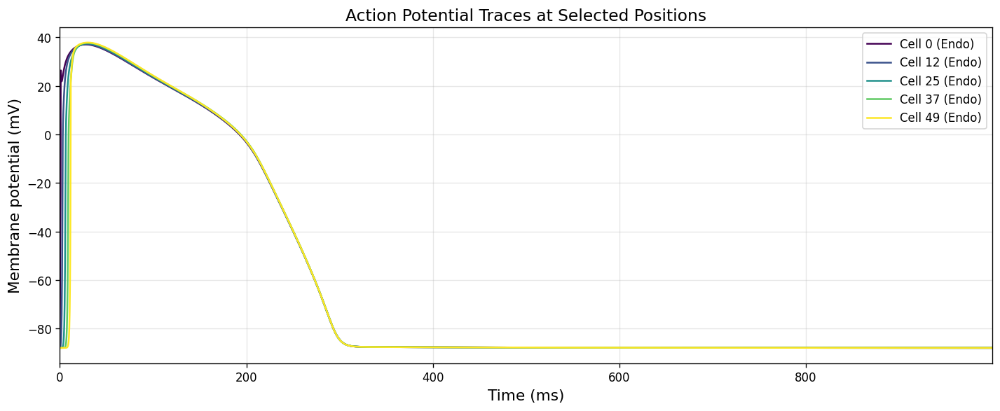

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))

sample_cells = [0, n_cells//4, n_cells//2, 3*n_cells//4, n_cells-1]
colors = plt.cm.viridis(np.linspace(0, 1, len(sample_cells)))

type_names = {0: 'Endo', 1: 'Epi', 2: 'M'}
for idx, c in enumerate(sample_cells):
    label = f"Cell {c} ({type_names[celltypes[c]]})"
    ax.plot(t_rec, V_rec[:, c], color=colors[idx], linewidth=1.5, label=label)

ax.set_xlabel('Time (ms)', fontsize=13)
ax.set_ylabel('Membrane potential (mV)', fontsize=13)
ax.set_title('Action Potential Traces at Selected Positions', fontsize=14)
ax.legend(fontsize=10, loc='upper right')
ax.set_xlim(t_rec[0], t_rec[-1])
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


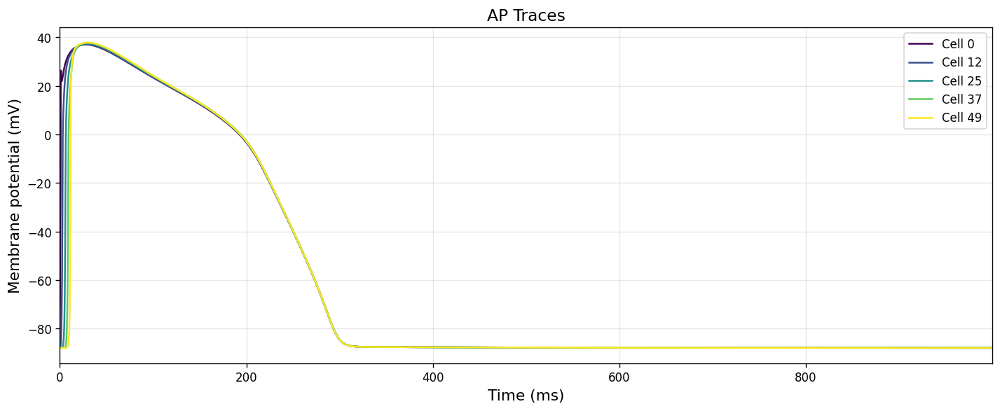

In [21]:
# --- Plot AP traces for endocardial cells only (celltype == 0) ---
fig, ax = plt.subplots(figsize=(12, 5))

endo_cells = [i for i in [0, n_cells//4, n_cells//2, 3*n_cells//4, n_cells-1]
              if celltypes[i] == 0]
colors = plt.cm.viridis(np.linspace(0, 1, len(endo_cells)))

for idx, c in enumerate(endo_cells):
    ax.plot(t_rec, V_rec[:, c], color=colors[idx], linewidth=1.5,
            label=f"Cell {c}")

ax.set_xlabel('Time (ms)', fontsize=13)
ax.set_ylabel('Membrane potential (mV)', fontsize=13)
ax.set_title('AP Traces', fontsize=14)
ax.legend(fontsize=10, loc='upper right')
ax.set_xlim(t_rec[0], t_rec[-1])
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 5.2 — Conduction Velocity Measurement
Estimate the conduction velocity (CV) by measuring activation times (when V
crosses -30 mV on the upstroke) at each cell position.


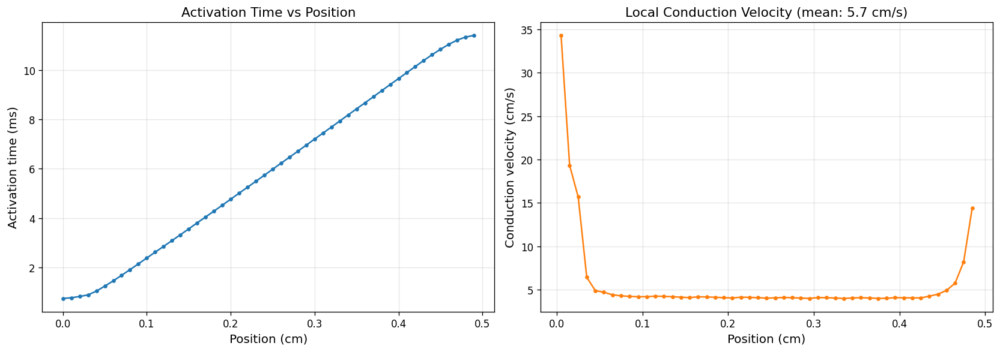

In [12]:
threshold = -30.0
activation_times = np.full(n_cells, np.nan)

for c in range(n_cells):
    trace = V_rec[:, c]
    for i in range(1, len(trace)):
        if trace[i-1] < threshold and trace[i] >= threshold:
            frac = (threshold - trace[i-1]) / (trace[i] - trace[i-1])
            activation_times[c] = t_rec[i-1] + frac * (t_rec[i] - t_rec[i-1])
            break

positions = np.arange(n_cells) * dx  # cm
valid = ~np.isnan(activation_times)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(positions[valid], activation_times[valid], 'o-', markersize=3, linewidth=1.5)
ax.set_xlabel('Position (cm)', fontsize=12)
ax.set_ylabel('Activation time (ms)', fontsize=12)
ax.set_title('Activation Time vs Position', fontsize=13)
ax.grid(True, alpha=0.3)

ax = axes[1]
if np.sum(valid) > 2:
    at_valid = activation_times[valid]
    pos_valid = positions[valid]
    dpos = np.diff(pos_valid)
    dt_act = np.diff(at_valid)
    dt_act[dt_act == 0] = np.nan
    local_cv = dpos / dt_act * 100  # keep in cm/s
    mid_pos = (pos_valid[:-1] + pos_valid[1:]) / 2
    cv_valid = ~np.isnan(local_cv) & (local_cv > 0) & (local_cv < 500)
    if np.any(cv_valid):
        ax.plot(mid_pos[cv_valid], local_cv[cv_valid], 'o-', markersize=3, linewidth=1.5, color='tab:orange')
        mean_cv = np.nanmean(local_cv[cv_valid])
        ax.set_title(f'Local Conduction Velocity (mean: {mean_cv:.1f} cm/s)', fontsize=13)
    else:
        ax.set_title('Local Conduction Velocity', fontsize=13)
    ax.set_xlabel('Position (cm)', fontsize=12)
    ax.set_ylabel('Conduction velocity (cm/s)', fontsize=12)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### 5.3 Animation of the propagation


In [18]:
from matplotlib.animation import FuncAnimation
from matplotlib import rc
from IPython.display import HTML

# Enable jshtml rendering (works in Google Colab)
rc('animation', html='jshtml')

# --- Downsample time for smooth but fast animation ---
anim_skip = max(1, len(t_rec) // 400)          # ~400 frames max
t_anim = t_rec[::anim_skip]
V_anim = V_rec[::anim_skip, :]

positions = np.arange(n_cells) * dx * 10        # convert cm -> mm for display

fig_anim, ax_anim = plt.subplots(figsize=(12, 5))
line, = ax_anim.plot(positions, V_anim[0, :], color='tab:red', linewidth=2)
time_text = ax_anim.text(0.02, 0.95, '', transform=ax_anim.transAxes,
                          fontsize=12, verticalalignment='top',
                          bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))

ax_anim.set_xlim(positions[0], positions[-1])
ax_anim.set_ylim(-100, 60)
ax_anim.set_xlabel('Position along chain (mm)', fontsize=13)
ax_anim.set_ylabel('Membrane potential (mV)', fontsize=13)
ax_anim.set_title('Action Potential Propagation — Animation', fontsize=14)
ax_anim.grid(True, alpha=0.3)

def _update(frame):
    line.set_ydata(V_anim[frame, :])
    time_text.set_text(f't = {t_anim[frame]:.1f} ms')
    return line, time_text

anim = FuncAnimation(fig_anim, _update, frames=len(t_anim),
                     interval=20, blit=True, repeat=True)

plt.close(fig_anim)           # prevent static duplicate
HTML(anim.to_jshtml())        # jshtml works in Colab (no ffmpeg needed)

## 6. Guide to Adjustable Variables

### 6.1 — Chain Geometry & Coupling

| Parameter | Default | Description | Experiment |
|-----------|---------|-------------|------------|
| `n_cells` | 50 | Number of cells in the chain | Increase to 100+ for longer fibres |
| `dx` | 0.01 cm | Cell spacing (= cell length) | Normally fixed at cell length |
| `D_gap` | 0.0012 cm^2/ms | Gap-junction diffusion coefficient | Decrease to simulate fibrosis (slow CV); set to 0 for uncoupled cells |

**Key insight:** Conduction velocity (CV) scales as sqrt(D). Reducing `D_gap` by 4x halves CV. Setting `D_gap = 0` creates completely uncoupled cells — each fires independently.

### 6.2 — Pacing Protocol

| Parameter | Default | Description | Experiment |
|-----------|---------|-------------|------------|
| `CL` | 1000 ms | Cycle length (1/heart rate) | 500 ms = 2 Hz; 300 ms = fast pacing; test rate dependence |
| `n_beats` | 5 | Beats to simulate | More beats -> closer to steady-state (but slower; ~2 min/beat for 50 cells) |
| `stim_cells` | [0-4] | Cells that receive the stimulus | Stimulate from middle for bidirectional propagation |
| `stim_amp` | -80 uA/uF | Stimulus amplitude | Must be suprathreshold |
| `stim_dur` | 1.0 ms | Stimulus duration | 0.5-2.0 ms; 1.0 ms needed for forward Euler |

### 6.3 — Cell Type Distribution

| Parameter | Default | Description | Experiment |
|-----------|---------|-------------|------------|
| `celltypes` | Transmural | Array of 0/1/2 per cell | Create uniform (all endo), or custom patterns |
| `endo_frac` | 0.35 | Fraction endocardial | Adjust transmural wedge composition |
| `m_frac` | 0.30 | Fraction M-cell | M-cells have longer APD -> transmural dispersion |

Cell-type differences affect: Ito, ICaL, IKr, IKs, IK1, INaCa, INaK, INaL, IKb, SERCA, calmodulin, and RyR release.

### 6.4 — Extracellular Ion Concentrations

| Parameter | Default | Description | Experiment |
|-----------|---------|-------------|------------|
| `nao` | 140 mM | Extracellular [Na+] | Decrease for hyponatremia |
| `ko` | 5.4 mM | Extracellular [K+] | Increase to 8-10 for hyperkalemia (depolarised resting potential, conduction slowing) |
| `cao` | 1.8 mM | Extracellular [Ca2+] | Increase/decrease affects ICaL, APD |

**Clinical relevance:** Hyperkalemia (increased ko) depolarises the resting potential, slows conduction, and can cause conduction block.

### 6.5 — Ion Channel Conductance Scaling (Drug Effects)

Each `scale_*` parameter is a multiplier on the maximum conductance. Set < 1 for channel block, > 1 for upregulation.

| Parameter | Channel | Clinical relevance |
|-----------|---------|-------------------|
| `scale_GNa` | INa (fast Na+) | Class I antiarrhythmics (e.g., flecainide) |
| `scale_GNaL` | INaL (late Na+) | Ranolazine targets this |
| `scale_Gto` | Ito (transient outward K+) | Brugada syndrome (loss of function) |
| `scale_PCa` | ICaL (L-type Ca2+) | Ca2+ channel blockers (verapamil, nifedipine) |
| `scale_GKr` | IKr (hERG) | **Most common drug target** — block causes QT prolongation |
| `scale_GKs` | IKs (slow delayed rectifier) | Long QT syndrome type 1 |
| `scale_GK1` | IK1 (inward rectifier) | Andersen-Tawil syndrome |
| `scale_Gncx` | INaCa (Na+/Ca2+ exchanger) | Heart failure remodelling |
| `scale_Pnak` | INaK (Na+/K+ pump) | Cardiac glycosides (digoxin) |

### 6.6 — Integration Parameters

| Parameter | Default | Description | Notes |
|-----------|---------|-------------|-------|
| `dt` | 0.02 ms | Time step | Decrease for better accuracy, increase for speed (may become unstable above ~0.05) |
| `record_dt` | 0.2 ms | Recording resolution | Decrease for finer voltage traces |


## 7. Example Experiments

Below are some ready-to-try parameter modifications. Uncomment any block,
re-run the parameter cell (Section 1), then re-run the simulation (Section 4).


In [ ]:
# ============================================================
# EXPERIMENT 1: IKr block (hERG block — QT prolongation)
# Simulates a typical drug side-effect causing long QT syndrome
# ============================================================
# scale_GKr = 0.3   # 70% block of IKr
# Expected: prolonged APD, greater transmural dispersion

# ============================================================
# EXPERIMENT 2: Hyperkalemia
# ============================================================
# ko = 8.0           # Elevated extracellular K+ (normal: 5.4)
# Expected: depolarised resting potential, reduced upstroke, slower conduction

# ============================================================
# EXPERIMENT 3: Reduced gap-junction coupling (fibrosis)
# ============================================================
# D_gap = 0.0003     # 75% reduction in coupling
# Expected: much slower conduction velocity, broader wavefront

# ============================================================
# EXPERIMENT 4: Uniform cell-type chain (all endocardial)
# ============================================================
# celltypes = np.zeros(n_cells, dtype=int)  # all endo
# Expected: no transmural APD dispersion

# ============================================================
# EXPERIMENT 5: Fast pacing (300 ms cycle length)
# ============================================================
# CL = 300; n_beats = 20
# Expected: shortened APD, rate-dependent effects

# ============================================================
# EXPERIMENT 6: Bidirectional propagation (stimulate from center)
# ============================================================
# stim_cells = list(range(n_cells//2 - 2, n_cells//2 + 3))
# Expected: wavefront propagates both directions from center

print("Uncomment an experiment above, re-run the parameter cell, then re-run the simulation.")


## 8. Technical Notes

### Numerical Method
- **Operator splitting**: The reaction (ionic) and diffusion (coupling) terms are
  split and solved sequentially each time step.
- **Forward Euler**: Simple explicit integration. Stable for `dt <= 0.025 ms` with
  the default parameters. If you increase `D_gap` significantly, you may need to
  decrease `dt` for stability (CFL condition: `dt < dx^2 / (2D)`).
- **Numerical safeguards**: All exponential functions are clipped to prevent overflow.
  Gating variables are clipped to [0, 1]. Concentrations are floored at 1e-12.
  GHK current equations use L'Hopital's limit near V = 0.

### Boundary Conditions
- **No-flux (sealed-end)**: No current flows out of the chain ends. This is the
  standard choice for isolated tissue preparations.

### Limitations
- This is a **monodomain** 1D cable, not a bidomain or 2D/3D tissue model.
- The forward Euler method is first-order accurate. For publication-quality results,
  consider adaptive time-stepping or higher-order methods.
- Performance is moderate with pure NumPy. For large-scale simulations (>200 cells,
  many beats), consider using Numba `@njit` or compiled languages.

### Validation
The single-cell model equations are a direct translation of the published MATLAB
code from the O'Hara-Rudy model (2011). The coupling formulation follows standard
cardiac cable theory.
